# Neural Network (NN)
A purpose-built architecture for the exoplanet 3-class problem:

- **Per-feature numerical embedding** — each of the 17 features gets its own learned (1 → 8) projection, similar to FT-Transformer
- **Cross-feature self-attention** — one transformer block over the 17 feature tokens captures interactions that trees find via co-splits
- **Hierarchical output head** — a binary "habitable vs not" head and a 2-way "meso vs psychro" head, combined into 3-way probabilities

The hierarchy matches the natural class structure: the easy 700-sample boundary (thermoplanet vs everything else) and the hard 14-sample boundary (meso vs psychro) get separate capacity.

This notebook covers training and tuning. Seed-sweep evaluation comes in a follow-up notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import matthews_corrcoef, f1_score

from utils import load_and_filter, impute, split_and_balance, FEATURES
from utils.constants import CLASS_NAMES, CLASSES

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cpu


## Data preparation

Same pipeline as every other model — `load_and_filter` → `impute` (Tier 1–2) → `split_and_balance` (Tier 3–7 fit on train only, then SMOTE).

We then carve a stratified 20% slice off the balanced training set to use as a validation set for early stopping and tuning. Note: this validation set is post-SMOTE balanced, which is fine for monitoring training progress but is not a true held-out distribution — that's what `X_te` is for.

In [3]:
df = load_and_filter()
df = impute(df)

X_tr_full, y_tr_full, X_te, y_te, cw, _ = split_and_balance(
    df, random_state=SEED, scaler=StandardScaler(), smote_variant="standard",
)

# Coerce to numpy up front — split_and_balance returns pandas types
X_tr_np = np.asarray(X_tr_full, dtype=np.float32)
y_tr_np = np.asarray(y_tr_full, dtype=np.int64)
X_te_np = np.asarray(X_te,      dtype=np.float32)
y_te_np = np.asarray(y_te,      dtype=np.int64)

# Stratified val carve from the balanced training set
X_tr_arr, X_val_arr, y_tr_arr, y_val_arr = train_test_split(
    X_tr_np, y_tr_np,
    test_size=0.2, stratify=y_tr_np, random_state=SEED,
)

# To tensors
X_tr   = torch.tensor(X_tr_arr,  dtype=torch.float32, device=DEVICE)
y_tr   = torch.tensor(y_tr_arr,                       device=DEVICE)
X_val  = torch.tensor(X_val_arr, dtype=torch.float32, device=DEVICE)
y_val  = torch.tensor(y_val_arr,                      device=DEVICE)
X_test = torch.tensor(X_te_np,   dtype=torch.float32, device=DEVICE)
y_test = torch.tensor(y_te_np,                        device=DEVICE)

# Class weights ordered by class index 0, 1, 2
class_weights = torch.tensor(
    [cw[float(k)] for k in (0, 1, 2)], dtype=torch.float32, device=DEVICE,
)

N_FEATURES = X_tr.shape[1]

print(f"Train: {tuple(X_tr.shape)}  classes: {np.bincount(y_tr_arr)}")
print(f"Val:   {tuple(X_val.shape)}  classes: {np.bincount(y_val_arr)}")
print(f"Test:  {tuple(X_test.shape)}  classes: {np.bincount(y_te_np)}")
print(f"Class weights: {dict(zip(CLASS_NAMES, class_weights.tolist()))}")

Loaded: (5569, 18)
Nulls before imputation:
pl_orbper       260
pl_orbsmax     2237
pl_orbeccen    3315
pl_bmasse      2986
pl_rade        1373
pl_eqt         2402
st_teff         290
st_rad          321
st_mass         206
st_lum          675
st_met          424
st_logg         351
st_age         1246
P_GRAVITY         7
P_DENSITY         7
P_ESCAPE          7
sy_dist         118
dtype: int64

[Tier 2a] pl_orbeccen: filled 3315 with 0.0
[Tier 2b] pl_orbsmax: filled 2203 via Kepler's 3rd law
[Tier 2c] pl_orbper: filled 242 via Kepler's 3rd law (inverse)
[Tier 2d] st_lum: filled 362 via Stefan-Boltzmann law
[Tier 2e] pl_bmasse: filled 2972 via mass-radius relation
[Tier 2f] pl_rade: filled 1359 via inverse mass-radius relation
[Tier 2g] pl_eqt: filled 2073 via equilibrium temp formula
[Tier 2h-j] P_GRAVITY/DENSITY/ESCAPE: filled 0 via physics formulas

Nulls after Tier 2:
pl_orbper        18
pl_orbsmax       34
pl_orbeccen       0
pl_bmasse        14
pl_rade          14
pl_eqt          

## Architecture

Three modules:

- `NumericalFeatureEmbedding`: each scalar feature → an `embed_dim`-vector with its own weight (no weight sharing across features)
- `CrossFeatureAttention`: a single transformer block (multi-head self-attention + position-wise FFN) over the 17 feature tokens
- `ExoNet`: ties it together. Mean-pools attended tokens, concatenates with the raw features (so the head can see both transformed and original signals), then sends that through two heads

In [7]:
class NumericalFeatureEmbedding(nn.Module):
    def __init__(self, n_features, embed_dim):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_features, embed_dim) * 0.1)
        self.bias   = nn.Parameter(torch.zeros(n_features, embed_dim))

    def forward(self, x):
        return x.unsqueeze(-1) * self.weight + self.bias


class CrossFeatureAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, ff_dim, dropout):
        super().__init__()
        self.ln1  = nn.LayerNorm(embed_dim)
        self.attn = nn.MultiheadAttention(embed_dim, n_heads,
                                          batch_first=True, dropout=dropout)
        self.ln2  = nn.LayerNorm(embed_dim)
        self.ff   = nn.Sequential(
            nn.Linear(embed_dim, ff_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(ff_dim, embed_dim),
        )

    def forward(self, x):
        a = self.ln1(x)
        attn_out, _ = self.attn(a, a, a, need_weights=False)
        x = x + attn_out
        x = x + self.ff(self.ln2(x))
        return x


def make_mlp(in_dim, hidden_dim, out_dim, n_hidden_layers, dropout):
    """Build a [Linear, GELU, Dropout] x N + Linear out."""
    if n_hidden_layers == 0:
        return nn.Linear(in_dim, out_dim)
    layers = [nn.Linear(in_dim, hidden_dim), nn.GELU(), nn.Dropout(dropout)]
    for _ in range(n_hidden_layers - 1):
        layers += [nn.Linear(hidden_dim, hidden_dim), nn.GELU(), nn.Dropout(dropout)]
    layers.append(nn.Linear(hidden_dim, out_dim))
    return nn.Sequential(*layers)


class ExoNet(nn.Module):
    def __init__(self, n_features,
                 embed_dim=8, n_heads=2, ff_dim=16,
                 n_attn_blocks=1,
                 head_hidden=16, n_subtype_hidden=1, n_hab_hidden=0,
                 dropout=0.3):
        super().__init__()
        self.embed = NumericalFeatureEmbedding(n_features, embed_dim)
        self.gelu  = nn.GELU()
        self.attn_blocks = nn.ModuleList([
            CrossFeatureAttention(embed_dim, n_heads, ff_dim, dropout)
            for _ in range(n_attn_blocks)
        ])
        self.dropout = nn.Dropout(dropout)

        pooled_dim = embed_dim + n_features
        self.hab_head     = make_mlp(pooled_dim, head_hidden, 1, n_hab_hidden, dropout)
        self.subtype_head = make_mlp(pooled_dim, head_hidden, 2, n_subtype_hidden, dropout)

    def forward(self, x):
        tokens = self.gelu(self.embed(x))
        for block in self.attn_blocks:
            tokens = block(tokens)
        pooled = tokens.mean(dim=1)
        rep    = torch.cat([pooled, x], -1)
        rep    = self.dropout(rep)
        return self.hab_head(rep).squeeze(-1), self.subtype_head(rep)


m = ExoNet(N_FEATURES)
print(f"Total parameters (defaults): {sum(p.numel() for p in m.parameters()):,}")

Total parameters (defaults): 1,348


## Hierarchical loss

The two heads aren't trained independently — we combine them into 3-way probabilities and add an auxiliary BCE on the habitable head:

$$P(\text{non-hab}) = 1 - \sigma(z_{\text{hab}}), \quad P(\text{meso}) = \sigma(z_{\text{hab}}) \cdot \text{softmax}(z_{\text{sub}})_0, \quad P(\text{psychro}) = \sigma(z_{\text{hab}}) \cdot \text{softmax}(z_{\text{sub}})_1$$

$$\mathcal{L} = \text{NLL}(\log P, y, w) + \alpha \cdot \text{BCE}(z_{\text{hab}}, \mathbb{1}[y > 0])$$

The auxiliary BCE acts as additional supervision on the binary boundary even when the meso/psychro head is struggling. Class weights `w` come from `compute_class_weight("balanced", ...)` via `split_and_balance`.

In [8]:
def hierarchical_loss(hab_logit, subtype_logits, y, class_weights, alpha=0.5):
    """y: (B,) long tensor in {0=non-hab, 1=meso, 2=psychro}."""
    y_hab = (y > 0).float()
    bce   = F.binary_cross_entropy_with_logits(hab_logit, y_hab)

    log_hab     = F.logsigmoid(hab_logit)
    log_nonhab  = F.logsigmoid(-hab_logit)
    log_subtype = F.log_softmax(subtype_logits, dim=-1)

    log_p = torch.stack([
        log_nonhab,
        log_hab + log_subtype[:, 0],
        log_hab + log_subtype[:, 1],
    ], dim=-1)

    nll = F.nll_loss(log_p, y, weight=class_weights)
    return nll + alpha * bce, log_p


def predict(model, X, batch_size=128):
    """Returns (preds, log_probs) on the given data."""
    model.eval()
    preds, log_probs = [], []
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            hab, sub = model(X[i:i + batch_size])
            log_hab     = F.logsigmoid(hab)
            log_nonhab  = F.logsigmoid(-hab)
            log_subtype = F.log_softmax(sub, dim=-1)
            lp = torch.stack([log_nonhab,
                              log_hab + log_subtype[:, 0],
                              log_hab + log_subtype[:, 1]], dim=-1)
            log_probs.append(lp)
            preds.append(lp.argmax(dim=-1))
    return torch.cat(preds).cpu().numpy(), torch.cat(log_probs).cpu().numpy()

## Training loop

AdamW optimizer + `ReduceLROnPlateau` on validation MCC + early stopping. Tracks train loss, val loss, val MCC per epoch. Restores best-val-MCC weights at the end.

In [9]:
def train_exonet(model, X_tr, y_tr, X_val, y_val, class_weights, *,
                 lr=3e-4, weight_decay=1e-4, batch_size=32,
                 max_epochs=300, patience=25, alpha=0.5, verbose=True):
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=8,
    )

    train_ds     = TensorDataset(X_tr, y_tr)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    history = {"train_loss": [], "val_loss": [], "val_mcc": [], "lr": []}
    best_mcc, best_state, no_improve = -np.inf, None, 0

    for epoch in range(max_epochs):
        model.train()
        train_losses = []
        for Xb, yb in train_loader:
            optimizer.zero_grad()
            hab, sub = model(Xb)
            loss, _ = hierarchical_loss(hab, sub, yb, class_weights, alpha=alpha)
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())

        # Validation
        model.eval()
        with torch.no_grad():
            hab, sub = model(X_val)
            val_loss, _ = hierarchical_loss(hab, sub, y_val, class_weights, alpha=alpha)
        val_preds, _ = predict(model, X_val)
        val_mcc = matthews_corrcoef(y_val.cpu().numpy(), val_preds)

        history["train_loss"].append(float(np.mean(train_losses)))
        history["val_loss"].append(float(val_loss))
        history["val_mcc"].append(float(val_mcc))
        history["lr"].append(optimizer.param_groups[0]["lr"])
        scheduler.step(val_mcc)

        if val_mcc > best_mcc:
            best_mcc = val_mcc
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                if verbose:
                    print(f"Early stop at epoch {epoch+1} (best val MCC {best_mcc:.4f})")
                break

        if verbose and (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1:3d}  train {history['train_loss'][-1]:.4f}  "
                  f"val {history['val_loss'][-1]:.4f}  val MCC {val_mcc:.4f}  "
                  f"lr {optimizer.param_groups[0]['lr']:.2e}")

    model.load_state_dict(best_state)
    return model, history, best_mcc

## First training run

Default hyperparameters from the architecture sketch. We want to see:

- Does the loss decrease at all?
- Does the val MCC track the train loss reasonably (no obvious overfit)?
- Where does early stopping fire?

If all three look healthy, tuning is the next step.

Epoch  10  train 1.0191  val 0.9711  val MCC 0.5340  lr 3.00e-04
Epoch  20  train 0.7126  val 0.7061  val MCC 0.6499  lr 3.00e-04
Epoch  30  train 0.5343  val 0.5360  val MCC 0.7787  lr 3.00e-04
Epoch  40  train 0.4203  val 0.4019  val MCC 0.8662  lr 1.50e-04
Epoch  50  train 0.3868  val 0.3393  val MCC 0.9046  lr 1.50e-04
Epoch  60  train 0.3643  val 0.3542  val MCC 0.8649  lr 1.50e-04
Epoch  70  train 0.3159  val 0.2846  val MCC 0.9356  lr 1.50e-04
Epoch  80  train 0.3113  val 0.3275  val MCC 0.9155  lr 7.50e-05
Early stop at epoch 88 (best val MCC 0.9356)

Best val MCC: 0.9356
Test MCC:     0.6140
Test F1 macro: 0.6969


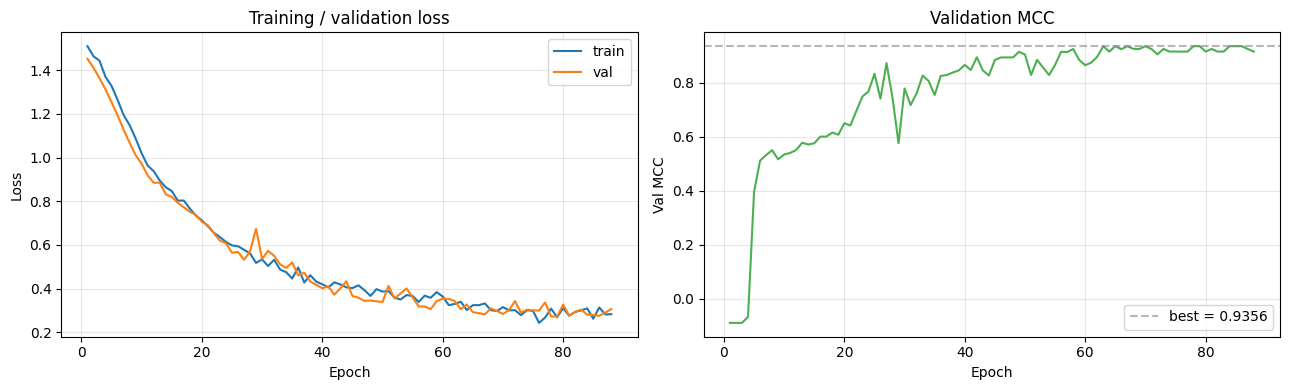

In [10]:
torch.manual_seed(SEED)
model = ExoNet(
    n_features=N_FEATURES,
    embed_dim=8, n_heads=2, ff_dim=16,
    head_hidden=16, dropout=0.3,
).to(DEVICE)

model, history, best_mcc = train_exonet(
    model, X_tr, y_tr, X_val, y_val, class_weights,
    lr=3e-4, weight_decay=1e-4, batch_size=32,
    max_epochs=300, patience=25, alpha=0.5,
)

# Sanity-check on test set
test_preds, _ = predict(model, X_test)
test_mcc = matthews_corrcoef(y_test.cpu().numpy(), test_preds)
test_f1m = f1_score(y_test.cpu().numpy(), test_preds, average="macro")
print(f"\nBest val MCC: {best_mcc:.4f}")
print(f"Test MCC:     {test_mcc:.4f}")
print(f"Test F1 macro: {test_f1m:.4f}")

# Loss + MCC curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
epochs = np.arange(1, len(history["train_loss"]) + 1)

axes[0].plot(epochs, history["train_loss"], label="train")
axes[0].plot(epochs, history["val_loss"],   label="val")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()
axes[0].set_title("Training / validation loss"); axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["val_mcc"], color="#4CAF50")
axes[1].axhline(best_mcc, color="#888", linestyle="--", alpha=0.6,
                label=f"best = {best_mcc:.4f}")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Val MCC"); axes[1].legend()
axes[1].set_title("Validation MCC"); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Metrics
### Classification Report + F1 Scores

### Confusion Matrix (Counts + Normalized)

## Interpretation: